# Resultados

Este notebook **solo lee resultados guardados**: la validación de 2016 y la ejecución única del test de 2017. No entrena, no carga el modelo y no recalcula el test, salvo dibujar las curvas con las probabilidades que `hotel-ml evaluate` guardó.

Las tablas completas están en el [informe final](../docs/informe_final.md).

In [1]:
%matplotlib inline

import matplotlib as mpl
import pandas as pd
from IPython.display import Markdown, display

from hotel_cancellation import champion, config
from hotel_cancellation.evaluation import plots

settings = config.get_settings()
mpl.rcParams.update(plots.STYLE)
pd.options.display.float_format = "{:.4f}".format

results = settings.final_evaluation_dir
record = champion.read_json(results / "record.json")["executions"][-1]
manifest = champion.read_json(settings.champion_dir / "manifest.json")
metrics = pd.read_csv(results / "metrics.csv")
bootstrap = pd.read_csv(results / "bootstrap.csv")
segments = pd.read_csv(results / "segments.csv")
monthly = pd.read_csv(results / "monthly.csv")
psi = pd.read_csv(results / "psi.csv")
predictions = pd.read_csv(results / "predictions.csv.gz")
selection = pd.read_csv(settings.validation_dir / "selection.csv")
business = pd.read_csv(settings.business_dir / "value_by_cost_scenario.csv")
importance = pd.read_csv(settings.interpretation_dir / "importance.csv")
winner = record["champion_name"]
models = ["random_forest", "xgboost", "mlp", "decision_tree", "logistic_regression", "dummy"]


def note(text):
    display(Markdown(text))


def count(number):
    return f"{int(number):,}".replace(",", " ")


def by_model(threshold_name, subset, columns):
    rows = metrics[(metrics["threshold_name"] == threshold_name) & (metrics["subset"] == subset)]
    return rows.set_index("model").loc[models, columns]


note(
    f"**Ejecución única:** {record['executed_at']}, código `{record['code']['commit'][:7]}`, "
    f"modelo `{record['champion_sha256'][:12]}…`, {count(record['test_rows'])} filas, "
    f"forzada: {record['forced']}."
)

**Ejecución única:** 2026-11-02T22:31:07+00:00, código `185aa76`, modelo `41d3a28592ae…`, 40 509 filas, forzada: False.

## 1. Selección en validación

La búsqueda usa `RandomizedSearchCV` con las cuatro ventanas expansivas de 2016. **La regla de 1 error estándar** mide, ventana a ventana, cuánto pierde cada modelo frente al mejor. Si la diferencia media cabe en un error estándar de esas diferencias, el modelo se considera empatado con él, y entre los empatados gana el más simple.

In [2]:
selection

,model,mean_roc_auc,std_roc_auc,mean_gap,paired_se,within_rule
0,logistic_regression,0.7927,0.0187,0.0246,0.0037,False
1,decision_tree,0.8007,0.0130,0.0165,0.0054,False
2,random_forest,0.8172,0.0231,0.0000,0.0000,True
3,xgboost,0.8162,0.0282,0.0011,0.0035,True
4,mlp,0.8053,0.0194,0.0119,0.0032,False


Random Forest y XGBoost quedan empatados, y Random Forest es el más simple en el orden que fijó el protocolo antes de comparar: regresión logística, árbol, Random Forest, XGBoost y MLP.

## 2. Calibración y umbral

Se compara sigmoide, isotónica o ninguna, ajustando en 2016T3 y midiendo el Brier en 2016T4. El umbral sale de los costes, que son **supuestos**: `t* = C_FP / (C_FP + C_FN)`.

In [3]:
decision = manifest["decision"]
note(
    f"**Calibración elegida:** `{manifest['model']['calibration']}`. "
    f"**Umbral servido:** {decision['threshold']}, con costes "
    f"{decision['false_positive_cost']:g}:{decision['false_negative_cost']:g}."
)
display(
    pd.Series(manifest["model"]["calibration_briers_on_2016q4"], name="Brier en 2016T4").to_frame()
)
pd.DataFrame(decision["contrast_on_2016q4"])

**Calibración elegida:** `isotonic`. **Umbral servido:** 0.25, con costes 1:3.

,Brier en 2016T4
none,0.1622
sigmoid,0.1602
isotonic,0.1592


,false_positive_cost,false_negative_cost,threshold,cost_at_threshold,empirical_best_threshold,cost_at_empirical_best
0,1.0000,2.0000,0.3333,0.3529,0.2800,0.3519
1,1.0000,3.0000,0.2500,0.4461,0.1800,0.4329
2,1.0000,5.0000,0.1667,0.5375,0.1500,0.4846


## 3. Comparación en el test de 2017

Es la tabla que pide el enunciado, ampliada con el baseline y con métricas que no dependen del umbral.

In [4]:
columns = [
    "roc_auc",
    "pr_auc",
    "brier",
    "calibration_slope",
    "accuracy",
    "precision",
    "recall",
    "f1",
]
by_model("decision", "all", [*columns, "cost_1_3"])

,roc_auc,pr_auc,brier,calibration_slope,accuracy,precision,recall,f1,cost_1_3
model,,,,,,,,,
random_forest,0.8175,0.7608,0.1627,0.9587,0.5698,0.4729,0.9409,0.6294,0.4761
xgboost,0.8164,0.7564,0.1639,0.9083,0.6062,0.4962,0.9214,0.6450,0.4549
mlp,0.8039,0.7654,0.1667,1.0167,0.6809,0.5599,0.8329,0.6696,0.4489
decision_tree,0.8040,0.7147,0.1660,1.1412,0.6240,0.5089,0.9031,0.6510,0.4512
logistic_regression,0.7956,0.7353,0.1700,0.9121,0.6424,0.5240,0.8618,0.6517,0.4650
dummy,0.5000,0.3883,0.2384,NaN,0.3883,0.3883,1.0000,0.5594,0.6117


Con un umbral fijo de 0.5, para comparar con otros trabajos. No es el umbral servido.

In [5]:
by_model("fixed_0.5", "all", ["accuracy", "precision", "recall", "f1", "tp", "fp", "fn", "tn"])

,accuracy,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,
random_forest,0.7484,0.6833,0.6563,0.6695,10324,4785,5406,19994
xgboost,0.7455,0.6721,0.6728,0.6724,10583,5163,5147,19616
mlp,0.7422,0.6982,0.5919,0.6406,9310,4025,6420,20754
decision_tree,0.7310,0.6274,0.7571,0.6861,11909,7074,3821,17705
logistic_regression,0.7363,0.7473,0.4850,0.5882,7629,2580,8101,22199
dummy,0.6117,NaN,0.0000,0.0000,0,0,15730,24779


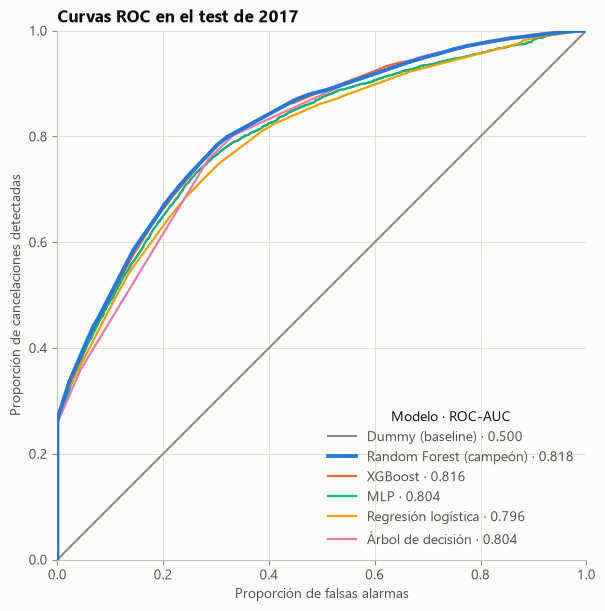

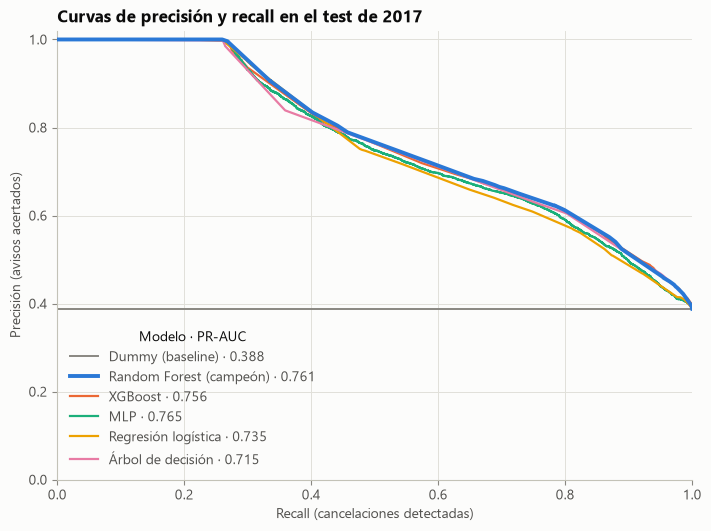

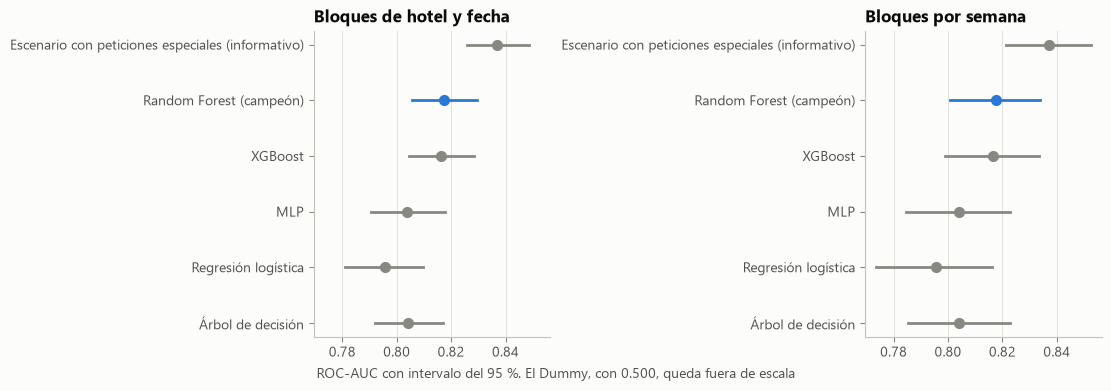

In [6]:
display(plots.roc_figure(predictions, winner))
display(plots.precision_recall_figure(predictions, winner))
display(plots.intervals_figure(bootstrap, winner))

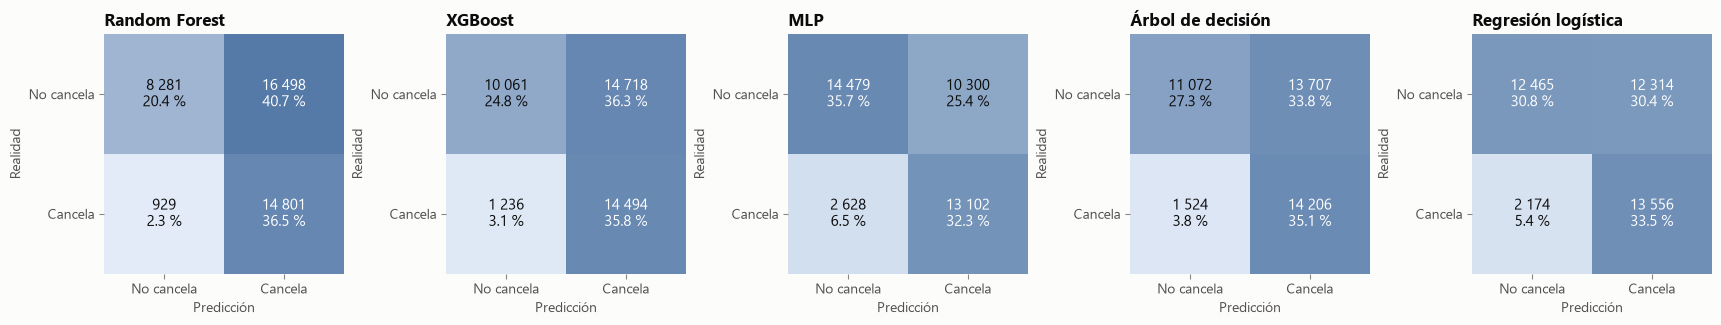

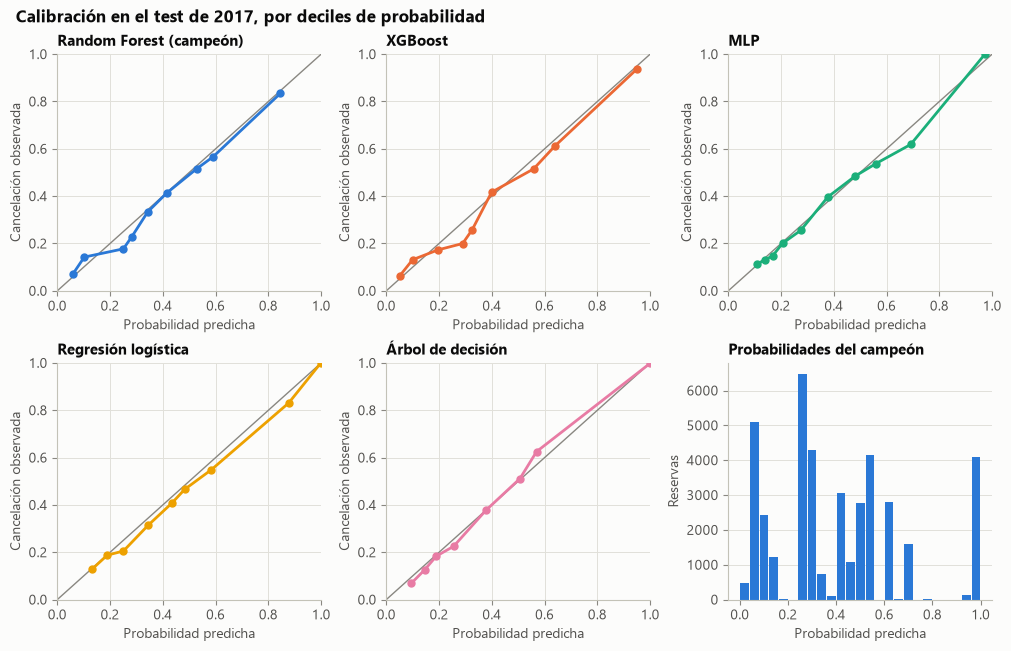

In [7]:
counts = by_model("decision", "all", ["tn", "fp", "fn", "tp"]).astype(int)
display(
    plots.confusion_figure(
        {plots.MODEL_LABELS[name]: tuple(counts.loc[name]) for name in models if name != "dummy"}
    )
)
display(plots.calibration_figure(predictions, winner))

## 4. La cifra global nunca va sola

`Non Refund` casi siempre se cancela, y las filas repetidas ayudan. Sin ellas, el problema es mucho más difícil.

In [8]:
champion_rows = metrics[(metrics["model"] == winner) & (metrics["threshold_name"] == "decision")]
display(
    champion_rows.set_index("subset").loc[
        ["all", "unique", "no_deposit", "non_refund"],
        ["rows", "prevalence", "roc_auc", "pr_auc", "brier", "precision", "recall", "f1"],
    ]
)
segments[segments["segment"].isin(["hotel", "market_segment"])][
    ["segment", "value", "rows", "prevalence", "roc_auc", "pr_auc", "brier"]
]

,rows,prevalence,roc_auc,pr_auc,brier,precision,recall,f1
subset,,,,,,,,
all,40509,0.3883,0.8175,0.7608,0.1627,0.4729,0.9409,0.6294
unique,29667,0.3300,0.7608,0.5820,0.1807,0.4082,0.9253,0.5665
no_deposit,36356,0.3187,0.7529,0.5456,0.1810,0.3926,0.9199,0.5503
non_refund,4126,0.9981,0.9998,1.0000,0.0010,0.9981,1.0000,0.9990


,segment,value,rows,prevalence,roc_auc,pr_auc,brier
0,hotel,City Hotel,27396,0.4262,0.8201,0.7917,0.1644
1,hotel,Resort Hotel,13113,0.3091,0.8020,0.6440,0.1592
2,market_segment,Aviation,106,0.2075,0.6282,0.4498,0.1520
3,market_segment,Complementary,206,0.1456,0.6182,0.2426,0.1264
4,market_segment,Corporate,1551,0.2560,0.8479,0.7341,0.1081
5,market_segment,Direct,4583,0.1560,0.6919,0.2691,0.1252
6,market_segment,Groups,5836,0.5826,0.9105,0.9456,0.0878
7,market_segment,Offline TA/TO,5646,0.3388,0.8537,0.8223,0.1111
8,market_segment,Online TA,22581,0.4098,0.7203,0.5863,0.2067


## 5. Deriva

El intervalo del bootstrap no cubre la deriva temporal, y por eso se publica mes a mes. El PSI compara cada variable con los datos de los que aprendió el modelo base.

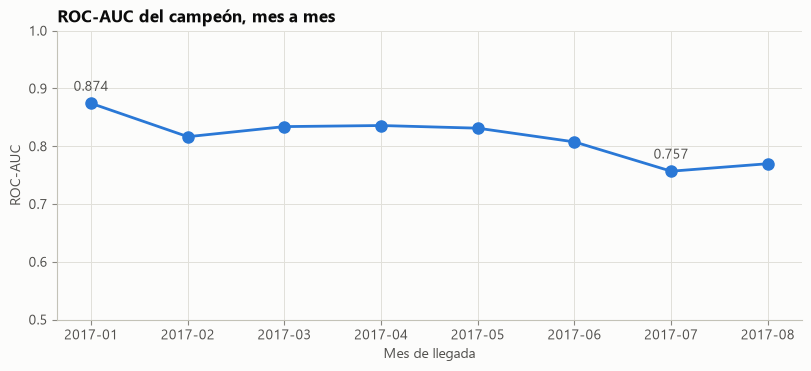

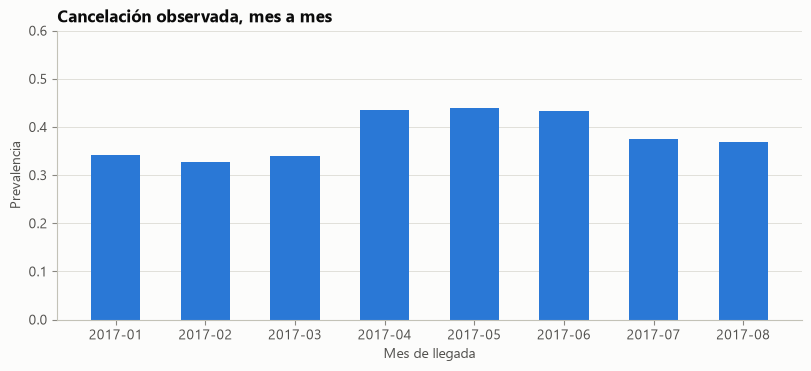

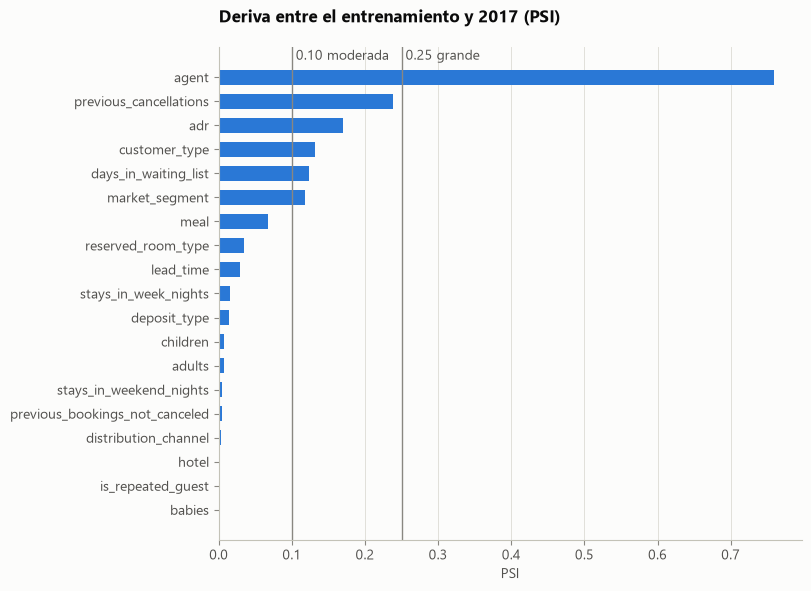

,month,rows,prevalence,roc_auc,brier
0,2017-01,3650,0.3422,0.8742,0.1299
1,2017-02,4142,0.3271,0.8165,0.1520
2,2017-03,4933,0.3387,0.8340,0.1461
3,2017-04,5648,0.4352,0.8358,0.1588
4,2017-05,6291,0.4389,0.8312,0.1597
5,2017-06,5632,0.4329,0.8075,0.1693
6,2017-07,5298,0.3745,0.7568,0.1890
7,2017-08,4915,0.3691,0.7697,0.1854


In [9]:
display(plots.monthly_auc_figure(monthly))
display(plots.monthly_prevalence_figure(monthly))
display(plots.drift_figure(psi))
monthly

## 6. Valor de negocio, con costes supuestos

**Los costes no son datos del hotel.** Cada fila indica qué haría el campeón si un falso positivo costara lo que dice el escenario.

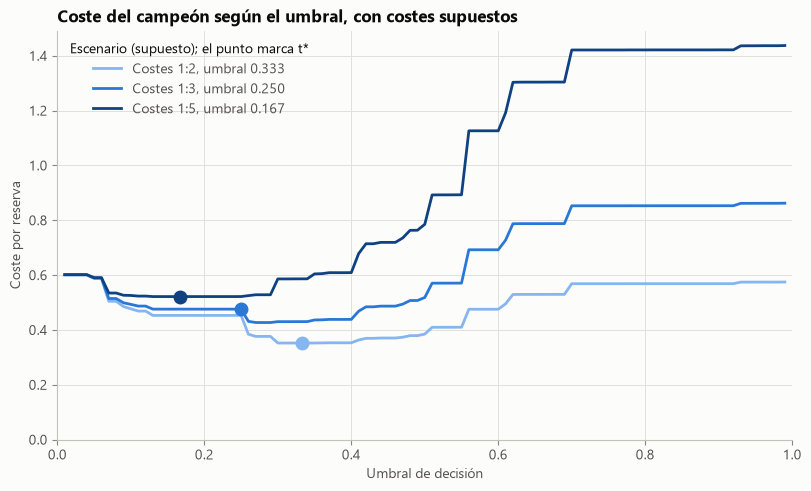

,false_positive_cost,false_negative_cost,threshold,recall,precision,flagged_share,cost_per_booking,cost_without_model,saving_per_booking
0,1.0000,2.0000,0.3333,0.7991,0.6124,0.5067,0.3524,0.6117,0.2593
1,1.0000,3.0000,0.2500,0.9409,0.4729,0.7726,0.4761,0.6117,0.1356
2,1.0000,5.0000,0.1667,0.9411,0.4729,0.7727,0.5217,0.6117,0.0900


In [10]:
display(plots.cost_figure(predictions, winner))
business[
    [
        "false_positive_cost",
        "false_negative_cost",
        "threshold",
        "recall",
        "precision",
        "flagged_share",
        "cost_per_booking",
        "cost_without_model",
        "saving_per_booking",
    ]
]

## 7. Interpretación

Sirve para interpretar, **no decide nada y no indica causas**. Tres métodos, por variable original.

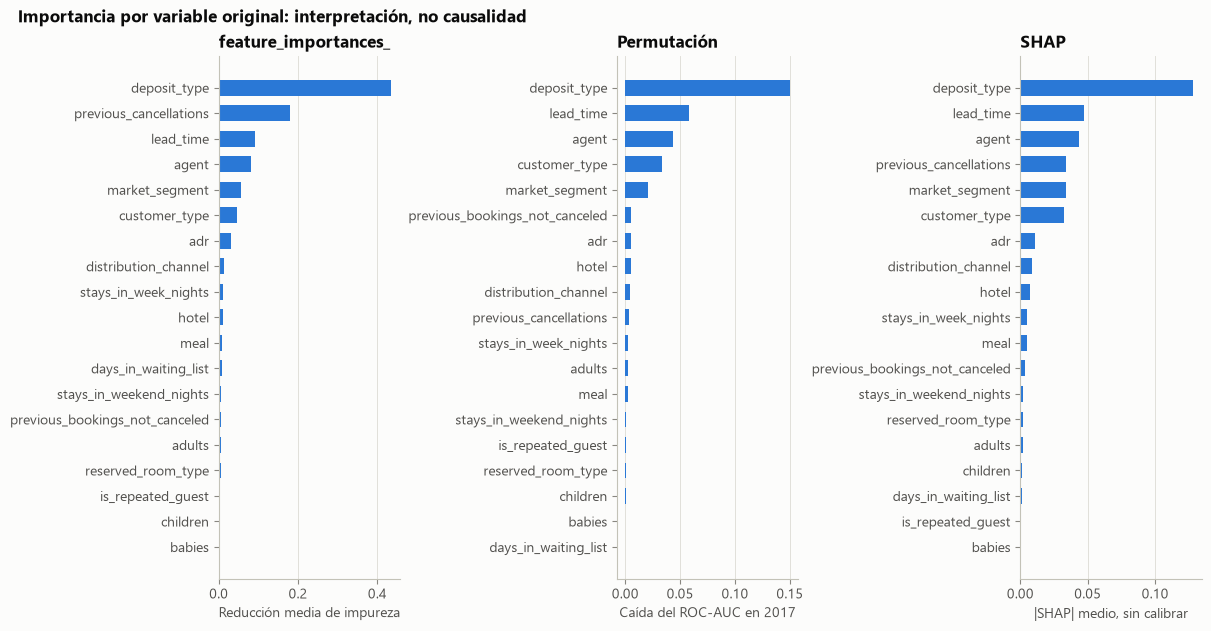

,variable,forest_importance,permutation_mean,permutation_std,shap_mean_abs
0,deposit_type,0.4352,0.1502,0.0018,0.1281
1,lead_time,0.0908,0.0583,0.0015,0.0475
2,agent,0.0821,0.0437,0.0008,0.0431
3,customer_type,0.0454,0.0332,0.0007,0.0326
4,market_segment,0.0568,0.0210,0.0008,0.0335
5,previous_bookings_not_canceled,0.0061,0.0053,0.0001,0.0032
6,adr,0.0318,0.0050,0.0005,0.0109
7,hotel,0.0098,0.0048,0.0006,0.0068
8,distribution_channel,0.0143,0.0041,0.0003,0.0086
9,previous_cancellations,0.1787,0.0030,0.0004,0.0340


In [11]:
display(plots.importance_figure(importance))
importance

## 8. Lo que el test señala y no se corrige

El modelo está congelado. Esto se declara, no se arregla mirando el test.

In [12]:
costs = by_model("decision", "all", ["cost_1_3"]).drop(index="dummy").sort_values("cost_1_3")
served = business[business["threshold"] == decision["threshold"]].iloc[0]
xgboost_gap = bootstrap[
    (bootstrap["model"] == "xgboost") & (bootstrap["blocks"] == "hotel_date")
].iloc[0]
pr_auc = by_model("decision", "all", ["pr_auc"]).drop(index="dummy").sort_values("pr_auc")
aucs = monthly.set_index("month")["roc_auc"]
note(
    f"1. **Con costes 1:3, el campeón es el más caro:** {costs.loc[winner, 'cost_1_3']:.4f} por "
    f"reserva, frente a {costs['cost_1_3'].iloc[0]:.4f} de `{costs.index[0]}`. La selección se "
    "hizo por ROC-AUC, como mandaba el protocolo.\n"
    f"2. **El umbral 0.25 avisa de demasiadas reservas:** el "
    f"{100 * served['flagged_share']:.1f} % de ellas, con {count(served['false_alarms'])} falsas "
    "alarmas. Cae justo antes de un escalón de la isotónica.\n"
    f"3. **Empate con XGBoost:** la diferencia pareada va de [{xgboost_gap['gap_ci_low']:+.4f}, "
    f"{xgboost_gap['gap_ci_high']:+.4f}].\n"
    f"4. **La mejor PR-AUC es de `{pr_auc.index[-1]}`:** {pr_auc['pr_auc'].iloc[-1]:.4f}, frente "
    f"a {pr_auc.loc[winner, 'pr_auc']:.4f} del campeón.\n"
    f"5. **El rendimiento cae al final:** de {aucs.max():.4f} en {aucs.idxmax()} a "
    f"{aucs.min():.4f} en {aucs.idxmin()}."
)

1. **Con costes 1:3, el campeón es el más caro:** 0.4761 por reserva, frente a 0.4489 de `mlp`. La selección se hizo por ROC-AUC, como mandaba el protocolo.
2. **El umbral 0.25 avisa de demasiadas reservas:** el 77.3 % de ellas, con 16 498 falsas alarmas. Cae justo antes de un escalón de la isotónica.
3. **Empate con XGBoost:** la diferencia pareada va de [-0.0033, +0.0008].
4. **La mejor PR-AUC es de `mlp`:** 0.7654, frente a 0.7608 del campeón.
5. **El rendimiento cae al final:** de 0.8742 en 2017-01 a 0.7568 en 2017-07.

Cambiar el umbral o el modelo ahora, viendo estas cifras, convertiría el test en validación y dejaría sin una estimación honesta del rendimiento. Quedan como propuesta de mejora para una siguiente versión, que debería validarse con datos nuevos.